# F4 · Visualización y comunicación de resultados

**MCDI500 · Sumativa 3 · Grupo 8.** Análisis descriptivo de matrícula de primer año de institutos profesionales en Chile durante 2025.

Se utilizan los tres CSV agregados versionados de F2, los [indicadores de concentración](../docs/indicadores_concentracion.csv) y los [metadatos F2](../docs/metadatos_fase2.json). La integridad de estos agregados y la concordancia de CR3 y HHI se verifican antes de graficar. La fuente es CNED–INDICES.

**Continuidad F3→F4:** F3 documenta equivalencia exacta con la salida de F2 en `evidencias/f3_equivalencia_f2.json`; F4 usa agregados interpretables en unidades originales de matrícula, no las columnas auxiliares one-hot o escaladas. Esta evidencia histórica se verifica como contrato documental, **sin sustituir** una nueva ejecución integral con la fuente original.


In [1]:
from io import BytesIO
from pathlib import Path
import json

from IPython.display import Image, display
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd

raiz = Path.cwd().resolve()
if raiz.name == 'F4':
    raiz = raiz.parent
datos = raiz / 'data' / 'processed'
documentacion = raiz / 'docs'
salidas = raiz / 'evidencias'
salidas.mkdir(exist_ok=True)

configuracion = {
    'institucion': ('Nombre Institución', 27),
    'region': ('Nombre Region', 16),
    'area': ('Area Conocimiento', 10),
}
conteo = 'matricula_primer_anio'

def cargar_resumen(dimension, categoria, n_categorias):
    tabla = pd.read_csv(datos / f'matricula_por_{dimension}.csv', encoding='utf-8-sig')
    matricula = tabla[conteo]
    if (len(tabla) != n_categorias or tabla[categoria].isna().any()
        or tabla[categoria].duplicated().any() or matricula.isna().any()
        or not pd.api.types.is_integer_dtype(matricula) or matricula.lt(0).any()):
        raise ValueError(f'Resumen de matrícula inválido: {dimension}')
    return tabla.sort_values([conteo, categoria], ascending=[False, True]).reset_index(drop=True)

resumenes = {
    dimension: cargar_resumen(dimension, categoria, n_categorias)
    for dimension, (categoria, n_categorias) in configuracion.items()
}
metadatos = json.loads((documentacion / 'metadatos_fase2.json').read_text(encoding='utf-8'))
# Contrato de continuidad histórica F3 -> F4, distinto de una nueva prueba con XLSX.
evidencia_f3 = json.loads((raiz / 'evidencias' / 'f3_equivalencia_f2.json').read_text(encoding='utf-8'))
if (not evidencia_f3.get('equivalencia_dataframe_exacto')
    or not evidencia_f3.get('equivalencia_csv')
    or evidencia_f3.get('filas') != 4731
    or evidencia_f3.get('columnas') != 68
    or evidencia_f3.get('matricula_primer_anio') != 137481
    or evidencia_f3.get('matricula_total') != 439607):
    raise ValueError('La evidencia versionada de equivalencia F2-F3 es inconsistente')
total = int(metadatos[conteo])
registros = next(iter(resumenes.values()))['registros'].sum()
if total <= 0 or any(t[conteo].sum() != total or t['registros'].sum() != registros
                     for t in resumenes.values()):
    raise ValueError('Los resúmenes discrepan de los metadatos o del universo de registros')

esperados = pd.read_csv(documentacion / 'indicadores_concentracion.csv', encoding='utf-8-sig').set_index('dimension')
indicadores = {}
for dimension, tabla in resumenes.items():
    categoria, n = configuracion[dimension]
    fraccion = tabla[conteo] / total
    cr3 = round(float(fraccion.head(3).sum()) * 100, 3)
    hhi = round(float(fraccion.pow(2).sum()) * 10000, 3)
    esperado = esperados.loc[categoria]
    if (esperado['grupos'], esperado['total_matricula_primer_anio'], esperado['cr3_pct'], esperado['hhi']) != (n, total, cr3, hhi):
        raise ValueError(f'CR3 o HHI discrepante con F2: {dimension}')
    indicadores[dimension] = {'Categorías': n, 'CR3 (%)': cr3, 'HHI': hhi}

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Liberation Sans', 'Arial', 'DejaVu Sans'],
    'font.size': 10, 'text.color': '#18232C', 'axes.labelcolor': '#41525D',
    'xtick.color': '#41525D', 'ytick.color': '#18232C',
    'axes.unicode_minus': False,
})
azul, claro, grilla = '#234B70', '#A3BCCB', '#DDE5E9'

def numero(valor):
    return f'{int(valor):,}'.replace(',', '.')

def porcentaje(valor, decimales=2):
    return f'{int(valor) / total * 100:.{decimales}f}'.replace('.', ',') + ' %'

def barras(ax, grupos, valores, destacados, limite, marcas, letra=9.3, eje='Matrículas de primer año'):
    posiciones = range(len(valores))
    ax.barh(posiciones, valores, height=.68, zorder=3,
            color=[azul if i < destacados else claro for i in posiciones])
    ax.set_yticks(posiciones, grupos)
    ax.invert_yaxis()
    ax.set(xlim=(0, limite), xticks=marcas)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: numero(v)))
    ax.tick_params(axis='both', length=0, pad=4, labelsize=letra)
    ax.xaxis.grid(True, color=grilla, linewidth=.65)
    for borde in ax.spines.values():
        borde.set_visible(False)
    ax.set_xlabel(eje, fontsize=9, labelpad=4)

def rotular(ax, valores, limite, destacados, cantidad=None, letra=9):
    for i, valor in enumerate(valores[:cantidad]):
        ax.text(valor + .014 * limite, i, numero(valor), va='center',
                fontsize=letra, weight='bold' if i < destacados else 'normal')

def exportar(figura, nombre):
    figura.savefig(salidas / nombre, dpi=340)
    with BytesIO() as vista:
        figura.savefig(vista, format='png', dpi=115)
        display(Image(data=vista.getvalue()))
    plt.close(figura)

print(f'{numero(registros)} registros agregados · {numero(total)} matrículas de primer año')
display(pd.DataFrame.from_dict(indicadores, orient='index'))

4.731 registros agregados · 137.481 matrículas de primer año


,Categorías,CR3 (%),HHI
institucion,27,53.916,1348.247
region,16,79.243,4402.463
area,10,79.806,2862.560


## Figura 1 · Distribución institucional

Las diez primeras instituciones se muestran en orden descendente. El azul oscuro identifica las tres con más matrícula. Su participación se calcula sobre las 27 instituciones observadas.

Tres instituciones líderes: 74.124 matrículas (53,92 % del total)


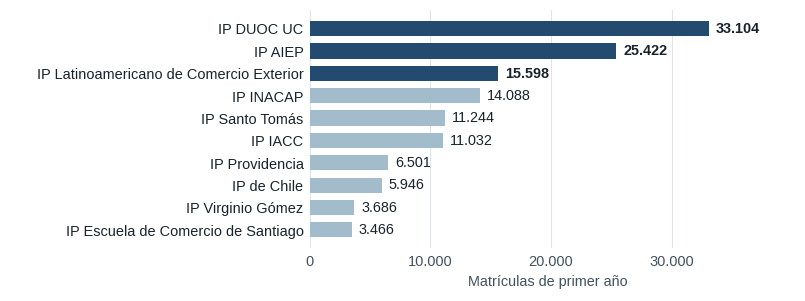

In [2]:
top = resumenes['institucion'].head(10)
nombres_instituciones = {
    'IP LATINOAMERICANO DE COMERCIO EXTERIOR': 'IP Latinoamericano de Comercio Exterior',
    'IP SANTO TOMÁS': 'IP Santo Tomás',
    'IP PROVIDENCIA': 'IP Providencia',
    'IP DE CHILE': 'IP de Chile',
    'IP VIRGINIO GÓMEZ': 'IP Virginio Gómez',
    'IP ESCUELA DE COMERCIO DE SANTIAGO': 'IP Escuela de Comercio de Santiago',
}
grupos = top['Nombre Institución'].replace(nombres_instituciones)
valores = top[conteo].tolist()
limite = (max(valores) * 1.19)
fig = plt.figure(figsize=(7, 2.62))
ax = fig.add_axes([.385, .175, .59, .79])
barras(ax, grupos, valores, 3, limite, range(0, int(limite), 10000), letra=9.1)
rotular(ax, valores, limite, 3)
exportar(fig, 'F4_top10_instituciones.png')
suma = sum(valores[:3])
print(f'Tres instituciones líderes: {numero(suma)} matrículas ({porcentaje(suma)} del total)')

## Figura 2 · Concentración territorial y por área

Ambos paneles usan la misma escala lineal, expresada en miles. El azul oscuro identifica los tres grupos líderes. ¹ Agricultura, Silvicultura, Pesca y Veterinaria.

Metropolitana: 89.674 (65,23 %)
Dos áreas líderes: 96.884 (70,47 %)


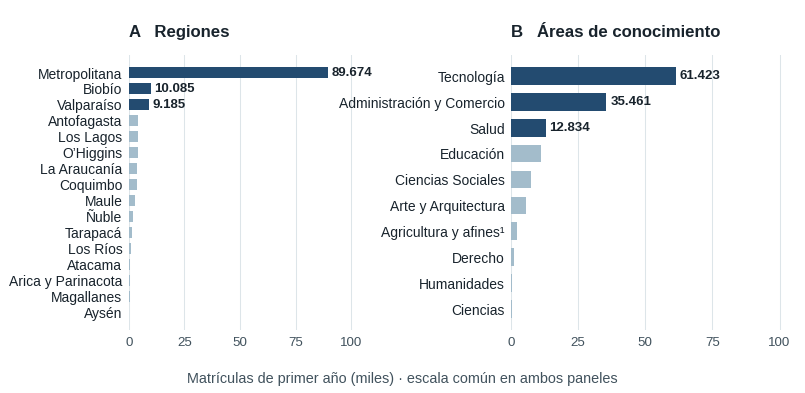

In [3]:
nombres_regiones = {
    'Región del Bío-Bío': 'Biobío',
    'Región del Gral. B. O`Higgins': 'O’Higgins',
    'Región de los Ríos': 'Los Ríos',
}
regiones = resumenes['region']
areas = resumenes['area']
rotulos_region = (
    regiones['Nombre Region'].replace(nombres_regiones)
    .str.replace(r'^Región (del |de )?', '', regex=True)
)
rotulos_area = areas['Area Conocimiento'].replace(
    {'Agricultura, Silvicultura, Pesca y Veterinaria': 'Agricultura y afines¹'}
)
valores_region = regiones[conteo].tolist()
valores_area = areas[conteo].tolist()

fig = plt.figure(figsize=(7, 3.42))
a = fig.add_axes([.16, .16, .29, .70])
b = fig.add_axes([.635, .16, .35, .70])
marcas = range(0, 100001, 25000)
for ax, grupos, valores in ((a, rotulos_region, valores_region), (b, rotulos_area, valores_area)):
    barras(ax, grupos, valores, 3, 105000, marcas, letra=8.7, eje='')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 1000:.0f}'))
    ax.tick_params(axis='x', labelsize=8.4)
    rotular(ax, valores, 105000, 3, cantidad=3, letra=8.3)
fig.text(.16, .905, 'A   Regiones', fontsize=10.5, weight='bold')
fig.text(.635, .905, 'B   Áreas de conocimiento', fontsize=10.5, weight='bold')
fig.text(.50, .026, 'Matrículas de primer año (miles) · escala común en ambos paneles',
         ha='center', fontsize=9, color='#41525D')
exportar(fig, 'F4_matricula_region_area.png')
print(f'{rotulos_region.iloc[0]}: {numero(valores_region[0])} ({porcentaje(valores_region[0])})')
print(f'Dos áreas líderes: {numero(sum(valores_area[:2]))} ({porcentaje(sum(valores_area[:2]))})')

## Figura 3 · Sensibilidad del total al registro de IP Santo Tomás

La bitácora F2 conserva el registro cuyo año de inicio figura como 2026. El escenario alternativo resta su aporte documentado en los metadatos F2. Ambas barras parten en cero.

Escenario observado: 137.481 · Sin el registro: 137.442
Variación: 39 matrículas (0,0284 %)


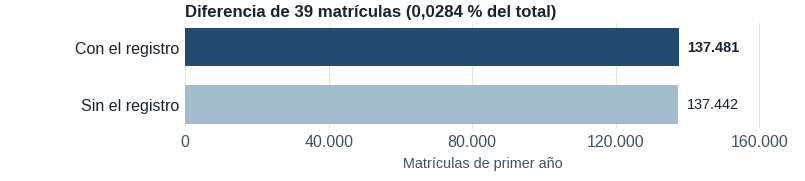

In [4]:
impacto = metadatos['impacto_anomalia_primer_anio']
if metadatos['validacion']['filas_anomalia_temporal'] != 1 or not 0 < impacto < total:
    raise ValueError('Metadatos F2 de sensibilidad inválidos')
sin_registro = total - impacto

fig = plt.figure(figsize=(7, 1.58))
ax = fig.add_axes([.23, .29, .74, .58])
barras(ax, ['Con el registro', 'Sin el registro'], [total, sin_registro],
       1, 166000, range(0, 160001, 40000), letra=10)
rotular(ax, [total, sin_registro], 166000, 1)
fig.text(.23, .93, f'Diferencia de {numero(impacto)} matrículas ({porcentaje(impacto, 4)} del total)',
         fontsize=10.5, weight='bold', va='center')
exportar(fig, 'F4_sensibilidad_santo_tomas.png')
print(f'Escenario observado: {numero(total)} · Sin el registro: {numero(sin_registro)}')
print(f'Variación: {numero(impacto)} matrículas ({porcentaje(impacto, 4)})')

## Interpretación científica de los resultados

**Instituciones.** Las tres primeras reúnen el 53,92 % de la matrícula observada. La concentración describe cómo se reparte el volumen entre las instituciones analizadas.

**Regiones y áreas.** La Región Metropolitana registra el 65,23 % del total. Tecnología y Administración y Comercio reúnen el 70,47 %. CR3 y HHI deben leerse dentro de cada dimensión, dadas las diferencias en el número y tipo de categorías.

**Sensibilidad.** El efecto de excluir el registro marcado es de 39 matrículas, el 0,0284 % del total de primer año.

**Alcance.** El estudio se circunscribe a la oferta agregada registrada en la fuente durante 2025. Evaluar acceso territorial requeriría denominadores de población y oferta. La matrícula tampoco mide calidad institucional ni resultados laborales.